In [ ]:
from pathlib import Path
from typing import Any, Dict, List
import json
import re
import statistics

from transformers import AutoTokenizer

DATA_DIR = Path("benchmarks_2") / "spider_data" / "format_data"
MODEL_NAME = "Qwen/Qwen3-0.6B"

# Student prompt length discovery for the augmented train.jsonl.
# The response comes from benchmarks_2/synid_aug_v2/final_merged.jsonl.
ACTIVE_PROMPT = "student"
SPLIT_FILES = {
    "train": "train.jsonl",
}
PROMPT_FIELD_CONFIGS = {
    "student": {"system_field": "system_prompt", "user_field": "user_prompt"},
    "teacher": {"system_field": "t_system_prompt", "user_field": "t_user_prompt"},
}
PROMPT_FIELDS = PROMPT_FIELD_CONFIGS[ACTIVE_PROMPT]

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True,
)


def read_jsonl_file(path: Path) -> List[Dict[str, Any]]:
    with path.open("r", encoding="utf-8") as file:
        return [json.loads(line) for line in file if line.strip()]


In [ ]:
raw_data_by_split = {
    split_name: read_jsonl_file(DATA_DIR / filename)
    for split_name, filename in SPLIT_FILES.items()
}

{
    "data_dir": str(DATA_DIR),
    "active_prompt": ACTIVE_PROMPT,
    "prompt_fields": PROMPT_FIELDS,
    "splits": {
        split_name: {
            "file": SPLIT_FILES[split_name],
            "rows": len(rows),
            "keys": sorted(rows[0].keys()) if rows else [],
            "has_prompt_fields": all(field in rows[0] for field in PROMPT_FIELDS.values()) if rows else False,
            "has_response": "response" in rows[0] if rows else False,
        }
        for split_name, rows in raw_data_by_split.items()
    },
}


{'data_dir': 'benchmarks_2\\spider_data\\format_data',
 'active_prompt': 'student',
 'prompt_fields': {'system_field': 'system_prompt',
  'user_field': 'user_prompt'},
 'splits': {'train': {'file': 'train.jsonl',
   'rows': 7000,
   'keys': ['response', 'system_prompt', 'user_prompt'],
   'has_prompt_fields': True,
   'has_response': True}}}

In [ ]:
def get_prompt_text(tokenizer, system_prompt: str, user_prompt: str, enable_thinking: bool = False) -> str:
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_prompt},
    ]
    try:
        return tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
            enable_thinking=enable_thinking,
        )
    except TypeError:
        return tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
        )


def token_length(tokenizer, text: str) -> int:
    inputs = tokenizer(text, return_tensors="pt")
    return inputs["input_ids"].shape[-1]


def summarize_lengths(lengths: List[int]) -> Dict[str, Any]:
    if not lengths:
        return {}

    lengths_sorted = sorted(lengths)
    n = len(lengths_sorted)

    def percentile(p: float) -> float:
        if n == 1:
            return float(lengths_sorted[0])
        idx = (n - 1) * p
        low = int(idx)
        high = min(low + 1, n - 1)
        frac = idx - low
        return lengths_sorted[low] * (1 - frac) + lengths_sorted[high] * frac

    return {
        "count": n,
        "min": min(lengths_sorted),
        "max": max(lengths_sorted),
        "mean": statistics.mean(lengths_sorted),
        "median": statistics.median(lengths_sorted),
        "p90": percentile(0.90),
        "p95": percentile(0.95),
        "p99": percentile(0.99),
    }


def extract_prompt_block(user_prompt: str, header: str) -> str:
    marker = re.search(rf"(?im)^\\s*{re.escape(header)}:\\s*\\n", user_prompt)
    if marker is None:
        return ""

    start = marker.end()
    next_header = re.search(
        r"(?im)^\\s*(QUESTION|EVIDENCE|SCHEMA|DATABASE SCHEMA|HERE IS A REFERENCE SOLUTION|ANSWER):\\s*$",
        user_prompt[start:],
    )
    end = start + next_header.start() if next_header else len(user_prompt)
    return user_prompt[start:end].strip()


In [ ]:
from tqdm.auto import tqdm


def analyze_dataset_token_lengths(
    dataset: List[Dict[str, Any]],
    tokenizer,
    split_name: str,
    system_field: str,
    user_field: str,
    response_field: str = "response",
    enable_thinking: bool = False,
):
    prompt_lengths = []
    prompt_plus_response_lengths = []
    response_only_lengths = []
    results = []

    for i, item in tqdm(enumerate(dataset), total=len(dataset), desc=f"Analyze {split_name}"):
        prompt_text = get_prompt_text(
            tokenizer=tokenizer,
            system_prompt=item[system_field],
            user_prompt=item[user_field],
            enable_thinking=enable_thinking,
        )
        response_text = item[response_field]

        prompt_len = token_length(tokenizer, prompt_text)
        full_len = token_length(tokenizer, prompt_text + response_text)
        response_len = full_len - prompt_len

        prompt_lengths.append(prompt_len)
        prompt_plus_response_lengths.append(full_len)
        response_only_lengths.append(response_len)

        results.append(
            {
                "split": split_name,
                "idx": i,
                "prompt_source": ACTIVE_PROMPT,
                "question": extract_prompt_block(item[user_field], "QUESTION"),
                "schema": extract_prompt_block(item[user_field], "DATABASE SCHEMA") or extract_prompt_block(item[user_field], "SCHEMA"),
                "reference_solution": extract_prompt_block(item[user_field], "HERE IS A REFERENCE SOLUTION"),
                "evidence": extract_prompt_block(item[user_field], "EVIDENCE"),
                "prompt_len": prompt_len,
                "prompt_plus_response_len": full_len,
                "response_len_only": response_len,
            }
        )

    summary = {
        "prompt_only": summarize_lengths(prompt_lengths),
        "response_only": summarize_lengths(response_only_lengths),
        "prompt_plus_response": summarize_lengths(prompt_plus_response_lengths),
    }

    return results, summary


In [ ]:
results_by_split = {}
summary = {}

for split_name, dataset in raw_data_by_split.items():
    split_results, split_summary = analyze_dataset_token_lengths(
        dataset,
        tokenizer,
        split_name=split_name,
        system_field=PROMPT_FIELDS["system_field"],
        user_field=PROMPT_FIELDS["user_field"],
        response_field="response",
        enable_thinking=False,
    )
    results_by_split[split_name] = split_results
    summary[split_name] = split_summary

summary


Analyze train: 100%|██████████| 7000/7000 [00:22<00:00, 312.37it/s]


{'train': {'prompt_only': {'count': 7000,
   'min': 267,
   'max': 1479,
   'mean': 446.93414285714283,
   'median': 382.0,
   'p90': 662.0,
   'p95': 746.0,
   'p99': 1453.0},
  'response_only': {'count': 7000,
   'min': 9,
   'max': 256,
   'mean': 35.04071428571429,
   'median': 31.0,
   'p90': 58.0,
   'p95': 67.0,
   'p99': 100.0},
  'prompt_plus_response': {'count': 7000,
   'min': 279,
   'max': 1647,
   'mean': 481.97485714285716,
   'median': 419.0,
   'p90': 690.0,
   'p95': 790.0,
   'p99': 1477.0}}}

In [ ]:
summary


{'train': {'prompt_only': {'count': 7000,
   'min': 267,
   'max': 1479,
   'mean': 446.93414285714283,
   'median': 382.0,
   'p90': 662.0,
   'p95': 746.0,
   'p99': 1453.0},
  'response_only': {'count': 7000,
   'min': 9,
   'max': 256,
   'mean': 35.04071428571429,
   'median': 31.0,
   'p90': 58.0,
   'p95': 67.0,
   'p99': 100.0},
  'prompt_plus_response': {'count': 7000,
   'min': 279,
   'max': 1647,
   'mean': 481.97485714285716,
   'median': 419.0,
   'p90': 690.0,
   'p95': 790.0,
   'p99': 1477.0}}}

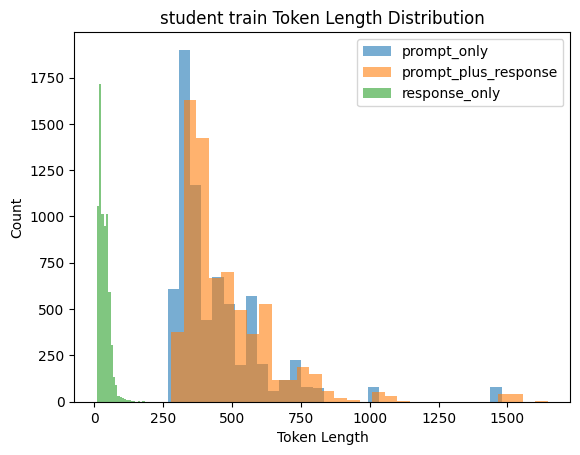

In [ ]:
import matplotlib.pyplot as plt

selected_split = next(iter(results_by_split))
results = results_by_split[selected_split]

prompt_lens = [x["prompt_len"] for x in results]
full_lens = [x["prompt_plus_response_len"] for x in results]
response_lens = [x["response_len_only"] for x in results]

plt.figure()
plt.hist(prompt_lens, bins=30, alpha=0.6, label="prompt_only")
plt.hist(full_lens, bins=30, alpha=0.6, label="prompt_plus_response")
plt.hist(response_lens, bins=30, alpha=0.6, label="response_only")

plt.xlabel("Token Length")
plt.ylabel("Count")
plt.title(f"{ACTIVE_PROMPT} {selected_split} Token Length Distribution")
plt.legend()
plt.show()


In [ ]:
selected_split = next(iter(results_by_split))
sorted(
    results_by_split[selected_split],
    key=lambda x: x["prompt_plus_response_len"],
    reverse=True,
)[:10]


[{'split': 'train',
  'idx': 3698,
  'prompt_source': 'student',
  'question': '',
  'schema': '',
  'reference_solution': '',
  'evidence': '',
  'prompt_len': 1473,
  'prompt_plus_response_len': 1647,
  'response_len_only': 174},
 {'split': 'train',
  'idx': 3697,
  'prompt_source': 'student',
  'question': '',
  'schema': '',
  'reference_solution': '',
  'evidence': '',
  'prompt_len': 1469,
  'prompt_plus_response_len': 1643,
  'response_len_only': 174},
 {'split': 'train',
  'idx': 3674,
  'prompt_source': 'student',
  'question': '',
  'schema': '',
  'reference_solution': '',
  'evidence': '',
  'prompt_len': 1457,
  'prompt_plus_response_len': 1558,
  'response_len_only': 101},
 {'split': 'train',
  'idx': 3661,
  'prompt_source': 'student',
  'question': '',
  'schema': '',
  'reference_solution': '',
  'evidence': '',
  'prompt_len': 1467,
  'prompt_plus_response_len': 1543,
  'response_len_only': 76},
 {'split': 'train',
  'idx': 3662,
  'prompt_source': 'student',
  'quest